# 04 · One-way analysis of risk factors, the coastal question, and a validation preview

**Goal:** before building any model, look at each candidate rating factor **on its own**: how often claims happen (frequency), how big they are (severity), and the loss cost per policy-year (pure premium), level by level. This is a **one-way analysis**, the classic first exhibit in an actuarial rate review. Then ask three skeptical questions:

1. **Is the effect real, or noise?** 95% confidence intervals and credibility flags.
2. **Is it stable?** Does it hold year after year, and without the three hurricane years (2011 Irene, 2012 Sandy, 2016 Matthew)?
3. **Is it really this factor, or another one hiding behind it?** Overlap between factors (confounding).

It also answers Theo's coastal question (Census coastline counties vs the broader "Tidewater Virginia" list) and previews the validation design (`docs/validation_plan.md`).

**Data:** `data/processed/va_model_data.parquet` (built by `src/build_dataset.py`), Virginia 2010–2025, losses in **2025 dollars**. Reusable code: `src/one_way.py`, `src/validation.py`. Findings are written up in `reports/03_one_way_findings.md`.

> Area-level analysis of aggregated public data. Nothing here is a prediction for an individual property.

In [1]:
import json
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
import statsmodels.api as sm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import build_dataset as bd      # our own modules in src/
import one_way as ow
import validation as val

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

# --- Chart style: the same quiet look as notebooks 01-03 ---------------------
BLUE = "#2a78d6"     # frequency
ORANGE = "#eb6834"   # severity / catastrophe years
AQUA = "#1baf7a"     # pure premium
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "font.size": 9.5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "hatch.color": SURFACE, "hatch.linewidth": 1.2, "legend.frameon": False,
})

def save(fig, name):
    path = FIG / f"04_{name}.png"
    fig.savefig(path)
    print(f"saved {path.relative_to(ROOT)}")

def rel_axis(ax, lo=0.25, hi=4):
    # Relativities on a LOG scale, so x2 and x0.5 are the same distance from 1.
    ax.set_yscale("log")
    ax.set_ylim(lo, hi)
    ticks = [t for t in [0.1, 0.25, 0.5, 1, 2, 4, 8, 16] if lo <= t <= hi]
    ax.yaxis.set_major_locator(mticker.FixedLocator(ticks))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
    ax.yaxis.set_minor_locator(mticker.NullLocator())
    ax.axhline(1, color=MUTED, lw=1, ls="--", zorder=1)

## 1. Load the table and re-check the totals
One row per **rating cell** (county × year × 8 building/policy features). We use **every** row, including the 1% of paid claims whose cell has no matching exposure (`exposure_matched = False`; see `docs/modeling_dataset.md`). That way frequency × severity = pure premium exactly. The week-3 frequency GLM will drop those rows.

In [2]:
cells = pd.read_parquet(bd.OUT_FILE)
tot = cells[["exposure", "claims", "losses_nominal", "losses_2025"]].sum()
assert abs(tot["exposure"] - bd.REFERENCE_TOTALS["exposure"]) < 0.01
assert tot["claims"] == bd.REFERENCE_TOTALS["claims"]
assert abs(tot["losses_nominal"] - bd.REFERENCE_TOTALS["losses_nominal"]) < 1
assert {"coastal", "coastal_tidal"} <= set(cells.columns)

FREQ = tot["claims"] / tot["exposure"]
SEV = tot["losses_2025"] / tot["claims"]
PP = tot["losses_2025"] / tot["exposure"]
print(f"{len(cells):,} cells | exposure {tot['exposure']:,.0f} policy-years | {tot['claims']:,.0f} paid claims")
print(f"Statewide: frequency {FREQ*1000:.2f} per 1,000 policy-years | severity ${SEV:,.0f} | pure premium ${PP:,.0f}")
assert abs(FREQ * SEV - PP) < 1e-9

assert val.cat_years(cells) == val.CAT_YEARS
CAT = list(val.CAT_YEARS)
by_year = cells.groupby("year")[["exposure", "claims", "losses_2025"]].sum()
print(f"Catastrophe years {CAT}: {by_year.loc[CAT, 'losses_2025'].sum() / tot['losses_2025']:.0%} of losses, "
      f"{by_year.loc[CAT, 'claims'].sum() / tot['claims']:.0%} of paid claims, "
      f"{by_year.loc[CAT, 'exposure'].sum() / tot['exposure']:.0%} of exposure")

252,531 cells | exposure 1,482,413 policy-years | 9,557 paid claims
Statewide: frequency 6.45 per 1,000 policy-years | severity $30,625 | pure premium $197
Catastrophe years [2011, 2012, 2016]: 68% of losses, 66% of paid claims, 20% of exposure


## 2. The tools, in plain English
- **Frequency** = paid claims ÷ exposure (claims per policy-year; shown per 1,000). **Severity** = dollars paid ÷ paid claims (average claim). **Pure premium** = dollars ÷ exposure = frequency × severity (expected loss cost per policy-year).
- **Relativity** = a level's value ÷ the **base level's** value. The base is the level with the most exposure, because its estimate is the most reliable. Example: if A/V-zone frequency is 9 per 1,000 and B/C/X is 3.7, then with A/V as base the B/C/X relativity is 3.7 ÷ 9 = 0.41: "41% of the base frequency," or "59% lower." Relativities are what a rating plan multiplies together, so they're the natural unit. Charts plot them on a **log scale**, so ×2 and ×0.5 sit the same distance from 1.
- **95% confidence interval (CI)**: a range of plausible values for the true long-run frequency. Narrow = well measured.
  - The textbook **Poisson CI** assumes claims arrive independently, like raindrops. Flood claims don't: one storm floods thousands of homes at once. So the counts vary far more than Poisson allows (**over-dispersion**). `one_way.py` measures how much more (the factor φ, "phi") from the year-by-level table and widens the intervals by √φ. **The whiskers in the charts are these widened intervals**; the plain-Poisson ones are in the tables for comparison.
- **Credibility**: how much to trust a level's own experience. The classic actuarial rule ("limited fluctuation") says **1,082 claims** give 90% confidence that the observed frequency is within ±5% of the truth. With n claims, credibility Z = √(n ÷ 1,082), capped at 1. Levels with **< 2% of exposure or < 30 claims** are flagged **low credibility** (hatched bars).
- **Importance score (F)**: how much better a "one frequency per level" model fits than "one frequency for everyone," measured by the drop in **deviance** (a goodness-of-fit score for count data; lower = better) per extra parameter, divided by φ. F ≈ 1 means "no better than storm-to-storm noise"; F in the tens or hundreds means the factor clearly matters. Severity gets the same score from a Gamma model.

## 3. One-way exhibits
Each exhibit has three panels sharing one x-axis (one scale per panel, so nothing is read off the wrong axis):
1. **Frequency relativity** with 95% CI whiskers (widened for over-dispersion).
2. **Severity** (orange) and **pure premium** (aqua) relativity.
3. **Exposure** share (bars; hatched = low credibility), with the paid-claim count printed on each bar.

In [3]:
FEATURES = ["flood_zone_group", "occupancy_group", "floors_group", "elevated", "primary_residence",
            "post_firm", "construction_band", "building_coverage_band", "coastal", "coastal_tidal",
            "county_group"]
NICE = {"flood_zone_group": "Flood zone", "occupancy_group": "Occupancy", "floors_group": "Floors",
        "elevated": "Elevated building", "primary_residence": "Primary residence",
        "post_firm": "Post-FIRM", "construction_band": "Year built",
        "building_coverage_band": "Coverage limit", "coastal": "Coastal (Census)",
        "coastal_tidal": "Tidal (Tidewater)", "county_group": "County group"}
# Natural order for ordered features; others go base level first, then by exposure.
ORDERS = {"floors_group": ["1", "2", "3+"],
          "construction_band": ["before 1960", "1960-1979", "1980-1999", "2000 or later"],
          "building_coverage_band": ["$0 (contents only)", "under $100K", "$100K-$249K", "$250K or more"]}

tables = {f: ow.one_way(cells, f) for f in FEATURES}
for f, t in tables.items():                       # basic checks on every table
    assert abs(t["exposure"].sum() - tot["exposure"]) < 0.01 and t["claims"].sum() == tot["claims"]
    assert t.loc[t.attrs["base"], "frequency_rel"] == 1
    assert np.allclose(t["frequency"] * t["severity"], t["pure_premium"])

def ordered(t):
    f = t.attrs["feature"]
    if f in ORDERS:
        return t.loc[ORDERS[f]]
    return t.sort_values(["is_base", "exposure"], ascending=False)

def show_table(t):
    t = ordered(t)
    out = pd.DataFrame({
        "exposure share": t["exposure_share"].map("{:.1%}".format),
        "paid claims": t["claims"].map("{:,.0f}".format),
        "freq /1,000": (t["frequency"] * 1000).map("{:.2f}".format),
        "Poisson 95% CI": [f"{a*1000:.2f}-{b*1000:.2f}" for a, b in zip(t["freq_lo"], t["freq_hi"])],
        "widened 95% CI": [f"{a*1000:.2f}-{b*1000:.2f}" for a, b in zip(t["freq_lo_od"], t["freq_hi_od"])],
        "freq rel": t["frequency_rel"].map("{:.2f}".format),
        "freq rel CI": [f"{a:.2f}-{b:.2f}" for a, b in zip(t["freq_rel_lo"], t["freq_rel_hi"])],
        "severity": t["severity"].map("${:,.0f}".format),
        "sev rel": t["severity_rel"].map("{:.2f}".format),
        "sev rel CI": [f"{a:.2f}-{b:.2f}" for a, b in zip(t["sev_rel_lo"], t["sev_rel_hi"])],
        "pure premium": t["pure_premium"].map("${:,.0f}".format),
        "pp rel": t["pure_premium_rel"].map("{:.2f}".format),
        "credibility Z": t["credibility_Z"].map("{:.2f}".format),
        "flag": np.where(t["is_base"], "BASE", np.where(t["low_credibility"], "low credibility", "")),
    }, index=t.index)
    a = t.attrs
    print(f"{NICE[a['feature']]}  (base: {a['base']}; over-dispersion phi = {a['phi_freq']:.0f} for "
          f"frequency, {a['phi_rel']:.0f} for relativities, {a['phi_sev']:.1f} for severity)")
    return out

LABEL = {True: "yes", False: "no"}

def wrap(s, w=9):
    s = LABEL.get(s, s) if isinstance(s, (bool, np.bool_)) else s
    out = "\n".join(textwrap.wrap(str(s), w, break_long_words=False)) or str(s)
    return out.replace("$", r"\$")      # a bare $ would switch matplotlib into math mode

def exhibit(axes, t, title, rel_lim=(0.25, 5), show_ylabels=True):
    # Draw one one-way exhibit into a column of 3 axes (shared x).
    ax1, ax2, ax3 = axes
    t = ordered(t)
    x = np.arange(len(t))
    lab = [wrap(i) for i in t.index]
    # 1. frequency relativity + CI
    yerr = [t["frequency_rel"] - t["freq_rel_lo"], t["freq_rel_hi"] - t["frequency_rel"]]
    ax1.errorbar(x, t["frequency_rel"], yerr=yerr, color=BLUE, lw=2, marker="o", ms=7,
                 capsize=4, elinewidth=1.2, mec=SURFACE, mew=1.5, zorder=3)
    for xi, v, isb in zip(x, t["frequency_rel"], t["is_base"]):
        if not isb:                       # the base is 1 by definition, no label needed
            ax1.annotate(f"{v:.2f}", (xi, v), xytext=(9, 10), textcoords="offset points",
                         va="center", fontsize=8.5, color=INK_2)
    rel_axis(ax1, *rel_lim)
    ax1.set_title(title)
    # 2. severity and pure premium relativity
    ax2.plot(x, t["severity_rel"], color=ORANGE, lw=2, marker="s", ms=7, mec=SURFACE, mew=1.5,
             label="severity", zorder=3)
    ax2.plot(x, t["pure_premium_rel"], color=AQUA, lw=2, marker="D", ms=7, mec=SURFACE, mew=1.5,
             label="pure premium", zorder=3)
    rel_axis(ax2, *rel_lim)
    # 3. exposure share, hatched if low credibility
    bars = ax3.bar(x, t["exposure_share"] * 100, width=0.6, color=BLUE, alpha=0.35,
                   edgecolor=SURFACE, linewidth=2)
    for b, low, n in zip(bars, t["low_credibility"], t["claims"]):
        if low:
            b.set_hatch("///"); b.set_alpha(0.6)
        ax3.annotate(f"{n:,.0f} claims" + ("\n(low credibility)" if low else ""), (b.get_x() + b.get_width() / 2, b.get_height()),
                     xytext=(0, 2), textcoords="offset points", ha="center", va="bottom",
                     fontsize=8, color=INK_2)
    ax3.set_ylim(0, max(t["exposure_share"] * 100) * 1.25)
    ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:.0f}%"))
    ax3.set_xticks(x, lab)
    ax3.set_xlim(-0.6, len(t) - 0.4)
    if show_ylabels:
        ax1.set_ylabel("Frequency\nrelativity")
        ax2.set_ylabel("Severity / pure\npremium relativity")
        ax3.set_ylabel("Exposure share")

def exhibit_figure(features, name, rel_lim=(0.25, 5), width_per=3.9):
    fig, axes = plt.subplots(3, len(features), figsize=(max(5.5, width_per * len(features)), 7.2),
                             sharex="col", squeeze=False,
                             gridspec_kw={"height_ratios": [1.3, 1, 0.8], "hspace": 0.12, "wspace": 0.28})
    for j, f in enumerate(features):
        exhibit(axes[:, j], tables[f], NICE[f], rel_lim, show_ylabels=(j == 0))
    axes[1, 0].legend(loc="lower left", fontsize=8.5)
    fig.text(0.0, -0.02, "Base level = relativity 1 (dashed line). Whiskers: 95% CI widened for "
             "over-dispersion. Hatched bars: low credibility (<2% of exposure or <30 claims). "
             "Virginia 2010-2025, 2025 dollars.", fontsize=8, color=MUTED)
    save(fig, name)
    plt.show()

In [4]:
show_table(tables["flood_zone_group"])

Flood zone  (base: A/V high risk; over-dispersion phi = 571 for frequency, 51 for relativities, 3.7 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
flood_zone_group,,,,,,,,,,,,,,
A/V high risk,51.0%,"6,856",9.06,8.85-9.28,5.15-15.96,1.00,1.00-1.00,"$32,637",1.00,1.00-1.00,$296,1.00,1.00,BASE
B/C/X moderate-low risk,49.0%,"2,701",3.72,3.58-3.86,1.51-9.16,0.41,0.30-0.56,"$25,519",0.78,0.72-0.85,$95,0.32,1.00,


In [5]:
show_table(tables["occupancy_group"])

Occupancy  (base: single-unit residential; over-dispersion phi = 362 for frequency, 11 for relativities, 2.1 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
occupancy_group,,,,,,,,,,,,,,
single-unit residential,89.3%,"8,266",6.25,6.11-6.38,4.14-9.42,1.00,1.00-1.00,"$25,088",1.00,1.00-1.00,$157,1.00,1.00,BASE
multi-unit residential,6.1%,799,8.91,8.30-9.55,2.38-33.33,1.43,1.12-1.82,"$58,864",2.35,2.11-2.61,$524,3.35,0.86,
non-residential,4.7%,492,7.08,6.47-7.74,1.32-38.08,1.13,0.84-1.53,"$77,799",3.10,2.72-3.54,$551,3.52,0.67,


In [6]:
show_table(tables["floors_group"])

Floors  (base: 2; over-dispersion phi = 373 for frequency, 13 for relativities, 3.8 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
floors_group,,,,,,,,,,,,,,
1,32.6%,"3,032",6.27,6.05-6.49,3.15-12.46,0.99,0.83-1.17,"$36,033",1.22,1.11-1.33,$226,1.20,1.00,
2,50.5%,"4,755",6.35,6.17-6.54,3.67-11.00,1.00,1.00-1.00,"$29,617",1.00,1.00-1.00,$188,1.00,1.00,BASE
3+,16.9%,"1,770",7.07,6.75-7.41,2.88-17.39,1.11,0.91-1.36,"$24,069",0.81,0.73-0.90,$170,0.90,1.00,


In [7]:
show_table(tables["construction_band"])

Year built  (base: 1980-1999; over-dispersion phi = 277 for frequency, 10 for relativities, 3.7 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
construction_band,,,,,,,,,,,,,,
before 1960,21.1%,"3,196",10.21,9.86-10.57,5.73-18.18,2.98,2.46-3.60,"$23,186",0.86,0.77-0.96,$237,2.56,1.00,
1960-1979,28.9%,"4,213",9.82,9.52-10.12,5.94-16.23,2.86,2.38-3.44,"$38,682",1.43,1.28-1.60,$380,4.10,1.00,
1980-1999,30.8%,"1,568",3.43,3.26-3.60,1.51-7.82,1.00,1.00-1.00,"$26,989",1.00,1.00-1.00,$93,1.00,1.00,BASE
2000 or later,19.1%,580,2.05,1.89-2.22,0.53-7.94,0.60,0.44-0.81,"$22,930",0.85,0.71-1.02,$47,0.51,0.73,


In [8]:
show_table(tables["building_coverage_band"])

Coverage limit  (base: $250K or more; over-dispersion phi = 283 for frequency, 23 for relativities, 3.2 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
building_coverage_band,,,,,,,,,,,,,,
$0 (contents only),1.4%,199,9.90,8.57-11.37,0.96-102.40,2.03,1.03-4.02,"$16,077",0.45,0.35-0.58,$159,0.92,0.43,low credibility
under $100K,9.4%,"1,294",9.24,8.74-9.76,3.70-23.10,1.90,1.41-2.55,"$20,147",0.57,0.51-0.63,$186,1.08,1.00,
$100K-$249K,28.4%,"3,676",8.73,8.45-9.02,5.07-15.03,1.79,1.45-2.21,"$29,264",0.82,0.76-0.89,$255,1.48,1.00,
$250K or more,60.8%,"4,388",4.87,4.73-5.02,2.96-8.01,1.00,1.00-1.00,"$35,515",1.00,1.00-1.00,$173,1.00,1.00,BASE


saved reports\figures\04_oneway_zone_occupancy_floors.png


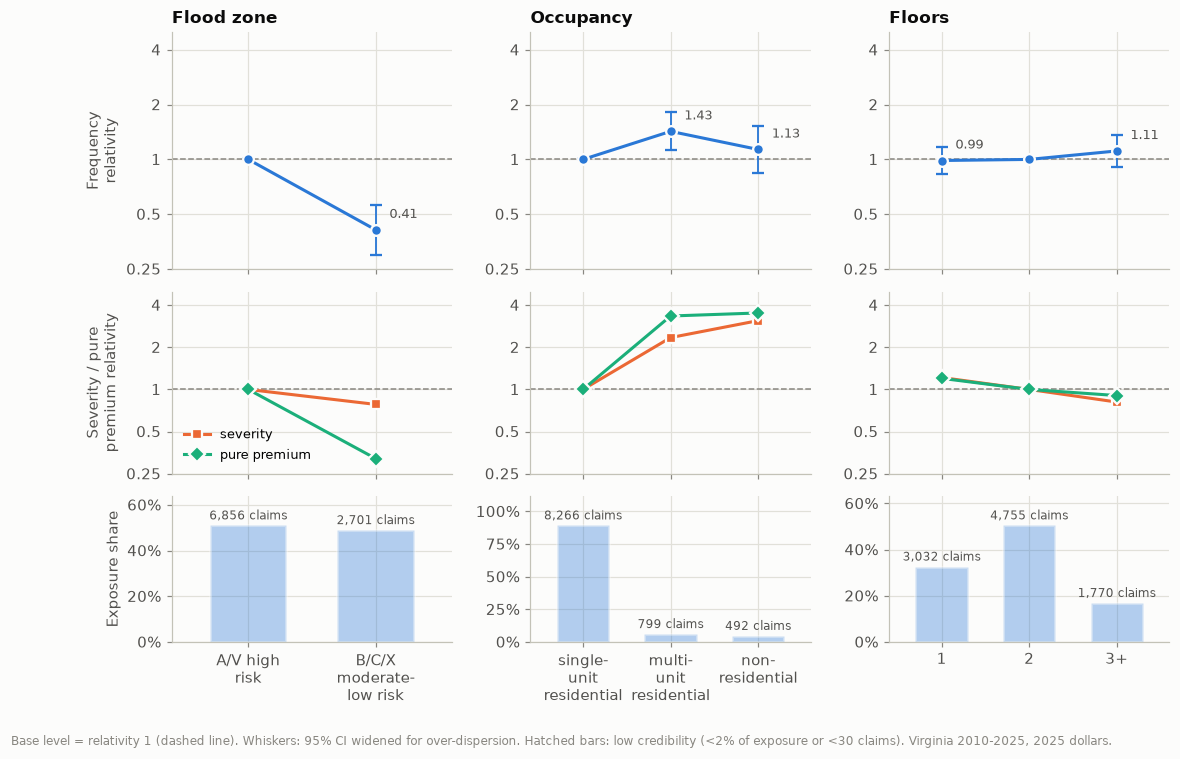

saved reports\figures\04_oneway_yearbuilt_coverage.png


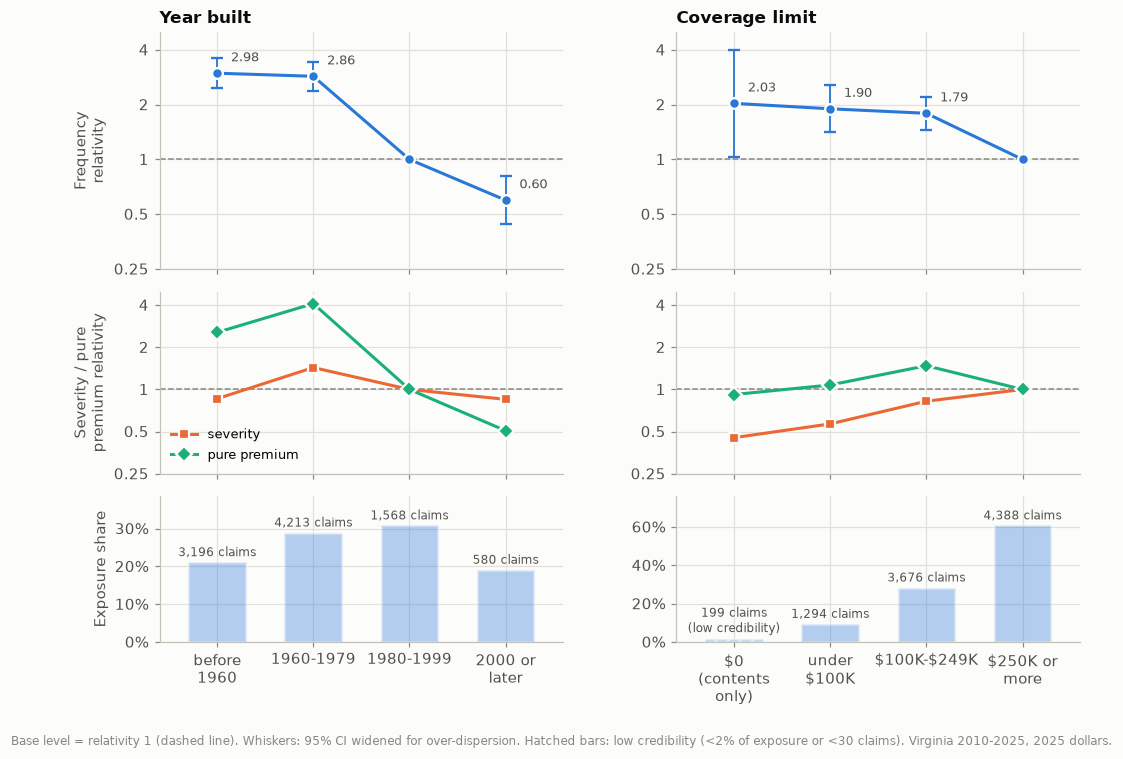

In [9]:
exhibit_figure(["flood_zone_group", "occupancy_group", "floors_group"], "oneway_zone_occupancy_floors")
exhibit_figure(["construction_band", "building_coverage_band"], "oneway_yearbuilt_coverage", width_per=5.4)

### Yes/no features

In [10]:
show_table(tables["elevated"])

Elevated building  (base: False; over-dispersion phi = 687 for frequency, 95 for relativities, 3.0 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
elevated,,,,,,,,,,,,,,
False,58.7%,"5,437",6.25,6.09-6.42,3.11-12.55,1.00,1.00-1.00,"$38,290",1.00,1.00-1.00,$239,1.00,1.00,BASE
True,41.3%,"4,120",6.72,6.52-6.93,3.02-14.97,1.08,0.72-1.60,"$20,511",0.54,0.50-0.57,$138,0.58,1.00,


In [11]:
show_table(tables["primary_residence"])

Primary residence  (base: True; over-dispersion phi = 541 for frequency, 10 for relativities, 2.7 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
primary_residence,,,,,,,,,,,,,,
True,72.2%,"6,648",6.21,6.06-6.36,3.55-10.86,1.00,1.00-1.00,"$25,128",1.00,1.00-1.00,$156,1.00,1.00,BASE
False,27.8%,"2,909",7.06,6.81-7.32,3.03-16.45,1.14,0.99-1.30,"$43,188",1.72,1.60-1.85,$305,1.95,1.00,


In [12]:
show_table(tables["post_firm"])

Post-FIRM  (base: False; over-dispersion phi = 542 for frequency, 8 for relativities, 3.7 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
post_firm,,,,,,,,,,,,,,
False,51.0%,"7,143",9.45,9.23-9.67,5.51-16.21,1.00,1.00-1.00,"$31,761",1.00,1.00-1.00,$300,1.00,1.00,BASE
True,49.0%,"2,414",3.32,3.19-3.46,1.31-8.41,0.35,0.31-0.40,"$27,266",0.86,0.79-0.94,$91,0.30,1.00,


In [13]:
show_table(tables["coastal"])

Coastal (Census)  (base: True; over-dispersion phi = 643 for frequency, 172 for relativities, 3.6 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
coastal,,,,,,,,,,,,,,
True,74.0%,"6,997",6.38,6.23-6.53,3.52-11.55,1.00,1.00-1.00,"$30,396",1.00,1.00-1.00,$194,1.00,1.00,BASE
False,26.0%,"2,560",6.64,6.39-6.91,2.49-17.74,1.04,0.58-1.89,"$31,251",1.03,0.94-1.12,$208,1.07,1.00,


In [14]:
show_table(tables["coastal_tidal"])

Tidal (Tidewater)  (base: True; over-dispersion phi = 667 for frequency, 230 for relativities, 3.4 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
coastal_tidal,,,,,,,,,,,,,,
True,89.2%,"8,154",6.17,6.04-6.30,3.52-10.81,1.00,1.00-1.00,"$29,414",1.00,1.00-1.00,$181,1.00,1.00,BASE
False,10.8%,"1,403",8.74,8.29-9.21,2.26-33.76,1.42,0.60-3.34,"$37,664",1.28,1.15-1.42,$329,1.81,1.00,


saved reports\figures\04_oneway_yes_no.png


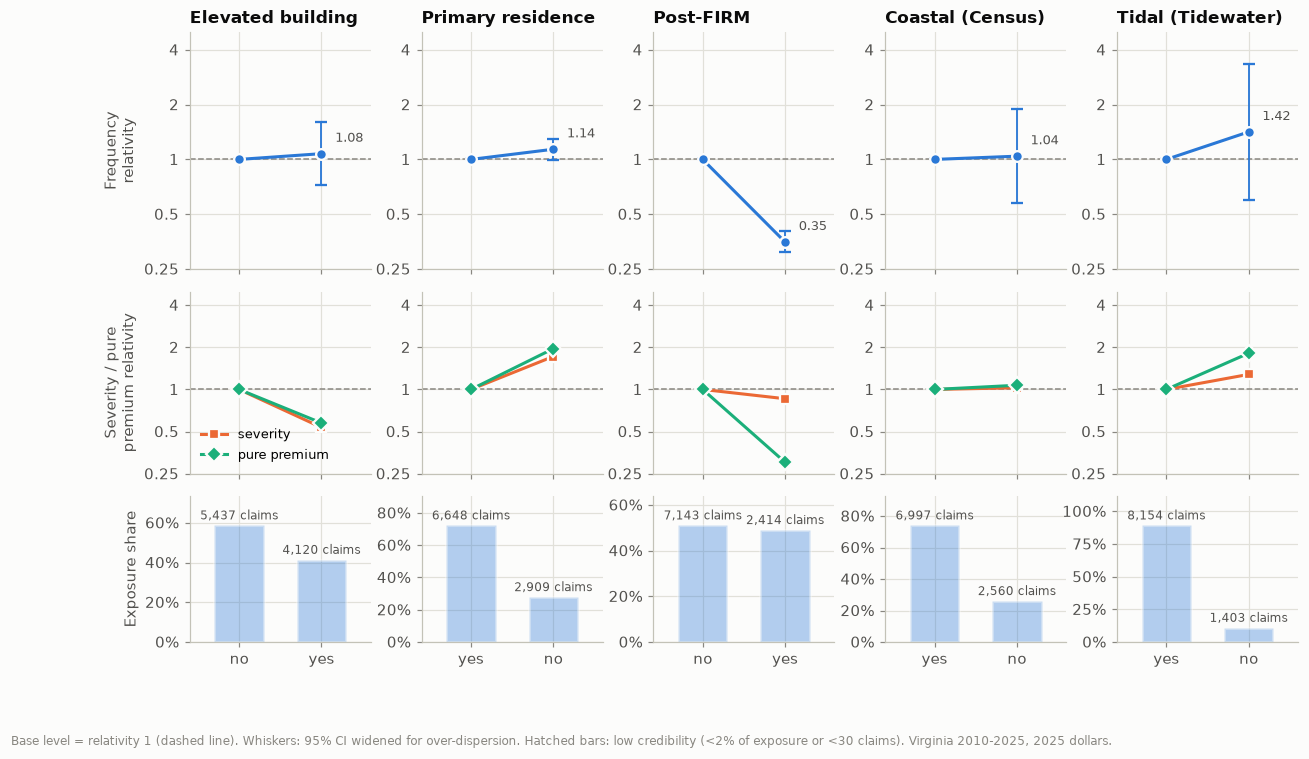

In [15]:
exhibit_figure(["elevated", "primary_residence", "post_firm", "coastal", "coastal_tidal"],
               "oneway_yes_no", width_per=2.6)

### County group
35 levels: the 32 counties with ≥ 5,000 policy-years plus 3 pooled groups. The base is Virginia Beach (the most exposure). With this many levels a dot chart is easier to read than the three-panel exhibit.

saved reports\figures\04_oneway_county_group.png


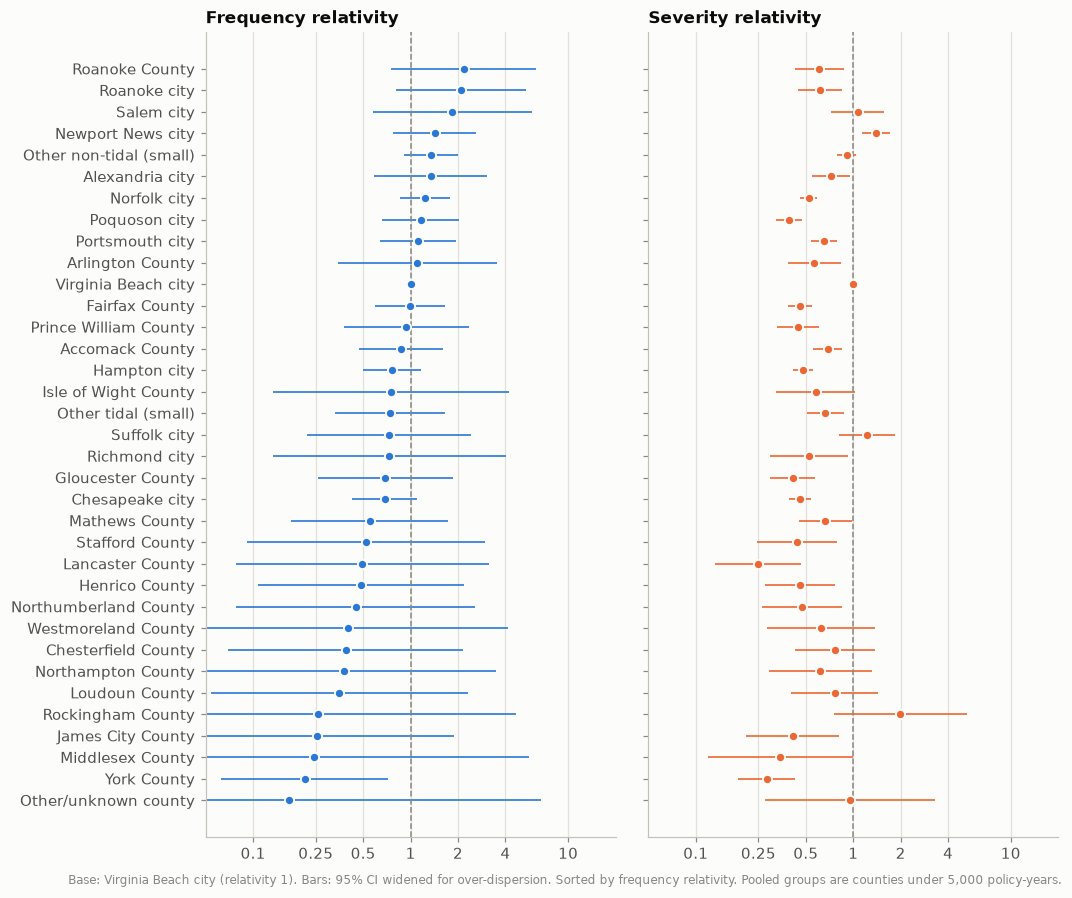

In [16]:
tc = tables["county_group"].copy()
names = cells.drop_duplicates("county").set_index("county")["county_name"]
tc["label"] = [names.get(i, i) for i in tc.index]
tc = tc.sort_values("frequency_rel")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 9.5), sharey=True, gridspec_kw={"wspace": 0.08})
y = np.arange(len(tc))
for ax, m, lo, hi, color, ttl in [(a1, "frequency_rel", "freq_rel_lo", "freq_rel_hi", BLUE, "Frequency relativity"),
                                  (a2, "severity_rel", "sev_rel_lo", "sev_rel_hi", ORANGE, "Severity relativity")]:
    ax.errorbar(tc[m], y, xerr=[tc[m] - tc[lo], tc[hi] - tc[m]], fmt="o", color=color, ms=6,
                elinewidth=1.1, capsize=0, mec=SURFACE, mew=1.2)
    ax.set_xscale("log"); ax.set_xlim(0.05, 20)
    ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 0.25, 0.5, 1, 2, 4, 10]))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.axvline(1, color=MUTED, ls="--", lw=1)
    ax.set_title(ttl); ax.grid(axis="y", visible=False)
a1.set_yticks(y, tc["label"])
fig.text(0.0, 0.065, "Base: Virginia Beach city (relativity 1). Bars: 95% CI widened for over-dispersion. "
         "Sorted by frequency relativity. Pooled groups are counties under 5,000 policy-years.",
         fontsize=8, color=MUTED)
save(fig, "oneway_county_group")
plt.show()

### Which features matter most on their own?
The importance score F (section 2) for frequency and for severity. Remember: F ≈ 1 is noise level. This is still **one-way**, so a factor can look important just because it travels with another one (section 5).

In [17]:
imp = pd.DataFrame([ow.importance(cells, f) for f in FEATURES]).set_index("feature")
imp["freq_rank"] = imp["freq_F"].rank(ascending=False).astype(int)
imp["sev_rank"] = imp["sev_F"].rank(ascending=False).astype(int)
imp.sort_values("freq_F", ascending=False).round(2)

,levels,freq_dev_drop,freq_F,phi_freq_rel,sev_dev_drop,sev_F,phi_sev,freq_rank,sev_rank
feature,,,,,,,,,
post_firm,2,2258.92,271.86,8.31,40.94,11.15,3.67,1,10
construction_band,4,3173.37,105.95,9.98,543.05,49.19,3.68,2,4
flood_zone_group,2,1701.97,33.24,51.20,113.01,30.46,3.71,3,6
building_coverage_band,4,866.93,12.57,22.98,374.45,38.76,3.22,4,5
occupancy_group,3,87.79,3.98,11.04,1335.66,319.15,2.09,5,1
primary_residence,2,32.90,3.45,9.53,630.60,235.25,2.68,6,3
county_group,35,1330.92,1.40,28.03,1315.62,12.05,3.21,7,9
floors_group,3,18.19,0.68,13.37,184.93,24.63,3.75,8,7
coastal_tidal,2,133.51,0.58,229.93,77.52,22.60,3.43,9,8


## 4. Stability: does each effect hold across years, and without the catastrophe years?
A factor that only matters in one storm year is less trustworthy: next year's storm may hit a different place. For each feature we follow its **main contrast** (one level vs the base) year by year.

- **Lines:** the relativity in each year. Hollow markers mean fewer than 30 paid claims in that level that year, so treat those points as noise. Orange bands mark the catastrophe years.
- **Solid gray line:** the all-years relativity. **Dashed:** excluding 2011, 2012, and 2016.

In [18]:
CONTRAST = {"flood_zone_group": "B/C/X moderate-low risk", "post_firm": True,
            "construction_band": "before 1960", "building_coverage_band": "under $100K",
            "occupancy_group": "multi-unit residential", "elevated": True, "primary_residence": False,
            "floors_group": "3+", "coastal": False, "coastal_tidal": False}
ex_cat = ow.exclude_years(cells, CAT)
cat_only = cells[cells["year"].isin(CAT)]
train, test = val.time_holdout(cells)

def rel_of(df, f, lvl, base, m="frequency"):
    t = df.groupby(f, observed=True)[["exposure", "claims", "losses_2025"]].sum()
    if m == "frequency":
        v = t["claims"] / t["exposure"]
    else:
        v = t["losses_2025"] / t["claims"]
    return v[lvl] / v[base]

rows, yearly = [], {}
for f, lvl in CONTRAST.items():
    base = tables[f].attrs["base"]
    yr = ow.by_year(cells, f, base=base)
    yr = yr[yr[f] == lvl].set_index("year")
    yearly[f] = yr
    allrel = tables[f].loc[lvl, "frequency_rel"]
    usable = yr[yr["claims"] >= 10]           # years with at least 10 claims in the level
    same = (np.sign(np.log(usable["frequency_rel"])) == np.sign(np.log(allrel))).mean()
    exrel = rel_of(ex_cat, f, lvl, base)
    catrel = rel_of(cat_only, f, lvl, base)
    # Verdict rules (simple, stated up front):
    #  1. "flips": the relativity is on the other side of 1 in cat years vs normal years
    #  2. "storm-dependent": cat-year and normal-year relativities differ by more than 2x
    #  3. otherwise "stable" if >= 75% of usable years point the same way as all years,
    #     "mostly stable" if >= 60%, else "mixed"
    flips = (np.sign(np.log(exrel)) != np.sign(np.log(catrel))) and min(abs(np.log(exrel)), abs(np.log(catrel))) > 0.1
    gap = max(exrel, catrel) / min(exrel, catrel)
    verdict = ("FLIPS: opposite direction in cat vs normal years" if flips else
               f"storm-dependent ({gap:.1f}x gap cat vs normal years)" if gap > 2 else
               "stable" if same >= 0.75 else "mostly stable" if same >= 0.6 else "mixed by year")
    rows.append({"feature": f, "level vs base": f"{LABEL.get(lvl, lvl)} vs {LABEL.get(base, base)}",
                 "freq rel: all years": allrel, "excl. cat years": exrel,
                 "cat years only": catrel,
                 "2010-2020": rel_of(train, f, lvl, base), "2021-2025": rel_of(test, f, lvl, base),
                 "sev rel: all": tables[f].loc[lvl, "severity_rel"],
                 "sev rel: excl. cat": rel_of(ex_cat, f, lvl, base, "severity"),
                 "years same direction": f"{same:.0%} of {len(usable)}", "verdict": verdict})
stability = pd.DataFrame(rows).set_index("feature")
stability.round(2)

,level vs base,freq rel: all years,excl. cat years,cat years only,2010-2020,2021-2025,sev rel: all,sev rel: excl. cat,years same direction,verdict
feature,,,,,,,,,,
flood_zone_group,B/C/X moderate-low risk vs A/V high risk,0.41,0.75,0.29,0.39,0.61,0.78,0.58,69% of 16,storm-dependent (2.6x gap cat vs normal years)
post_firm,yes vs no,0.35,0.33,0.36,0.34,0.38,0.86,0.83,100% of 16,stable
construction_band,before 1960 vs 1980-1999,2.98,2.77,3.09,3.06,2.25,0.86,0.74,100% of 16,stable
building_coverage_band,under $100K vs $250K or more,1.90,3.42,0.94,1.47,6.08,0.57,0.49,87% of 15,storm-dependent (3.6x gap cat vs normal years)
occupancy_group,multi-unit residential vs single-unit residential,1.43,1.46,1.31,1.39,0.92,2.35,3.09,73% of 11,mostly stable
elevated,yes vs no,1.08,0.70,1.42,1.11,0.71,0.54,0.64,25% of 16,FLIPS: opposite direction in cat vs normal years
primary_residence,no vs yes,1.14,1.28,0.96,1.06,1.20,1.72,2.71,75% of 16,stable
floors_group,3+ vs 2,1.11,1.33,0.86,0.99,1.14,0.81,1.16,69% of 13,FLIPS: opposite direction in cat vs normal years
coastal,no vs yes,1.04,3.43,0.41,0.90,4.54,1.03,1.64,75% of 16,FLIPS: opposite direction in cat vs normal years


saved reports\figures\04_stability_by_year.png


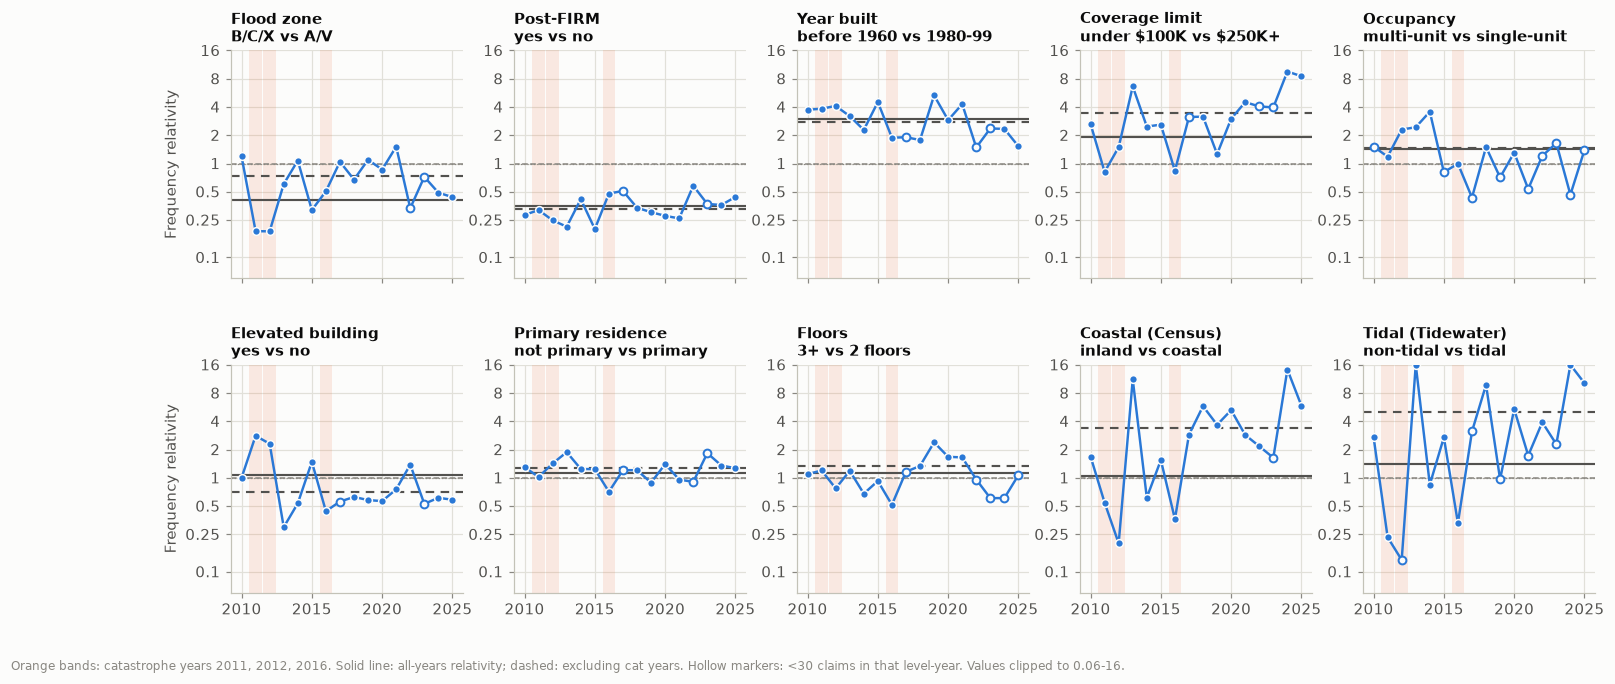

In [19]:
SUBTITLE = {"flood_zone_group": "B/C/X vs A/V", "post_firm": "yes vs no",
            "construction_band": "before 1960 vs 1980-99", "building_coverage_band": r"under \$100K vs \$250K+",
            "occupancy_group": "multi-unit vs single-unit", "elevated": "yes vs no",
            "primary_residence": "not primary vs primary", "floors_group": "3+ vs 2 floors",
            "coastal": "inland vs coastal", "coastal_tidal": "non-tidal vs tidal"}
fig, axes = plt.subplots(2, 5, figsize=(16, 6.4), sharex=True, gridspec_kw={"hspace": 0.38, "wspace": 0.22})
for ax, (f, yr) in zip(axes.ravel(), yearly.items()):
    for c in CAT:
        ax.axvspan(c - 0.45, c + 0.45, color=ORANGE, alpha=0.13, lw=0)
    v = yr["frequency_rel"].replace([np.inf, 0], np.nan).clip(0.06, 16)
    ax.plot(v.index, v, color=BLUE, lw=1.6, zorder=3)
    solid = yr["claims"] >= 30
    ax.scatter(v.index[solid], v[solid], color=BLUE, s=26, zorder=4, edgecolor=SURFACE, lw=1)
    ax.scatter(v.index[~solid], v[~solid], facecolor=SURFACE, edgecolor=BLUE, s=26, zorder=4, lw=1.3)
    ax.axhline(stability.loc[f, "freq rel: all years"], color=INK_2, lw=1.4)
    ax.axhline(stability.loc[f, "excl. cat years"], color=INK_2, lw=1.4, ls=(0, (4, 3)))
    rel_axis(ax, 0.06, 16)
    ax.axhline(1, color=MUTED, lw=0.8, ls=":")
    ax.set_title(f"{NICE[f]}\n{SUBTITLE[f]}", fontsize=9.5)
    ax.set_xticks([2010, 2015, 2020, 2025])
axes[0, 0].set_ylabel("Frequency relativity"); axes[1, 0].set_ylabel("Frequency relativity")
fig.text(0.0, 0.0, "Orange bands: catastrophe years 2011, 2012, 2016. Solid line: all-years relativity; dashed: "
         "excluding cat years. Hollow markers: <30 claims in that level-year. Values clipped to 0.06-16.",
         fontsize=8, color=MUTED)
save(fig, "stability_by_year")
plt.show()

**Reading this:**
- **Stable factors** keep their direction in (almost) every year and barely move without the hurricanes: **post-FIRM** (0.35 overall, 0.33 without cat years, same direction in all 16 years) and **year built** (pre-1960 about 2.8–3.1× the 1980–99 base either way). **Occupancy** and **primary residence** are mostly stable for frequency.
- **Flood zone is storm-dependent.** B/C/X buildings have 0.29× the A/V frequency in the hurricane years, but 0.75× in normal years. Hurricane storm surge hits exactly the mapped coastal floodplain. Ordinary-year flooding (heavy rain, flash floods) often happens outside the flood maps. The zone still matters in both regimes, just much more in storms.
- **Coverage band** (under \$100K vs \$250K+) is about 1 in cat years but 3.4× in normal years. Smaller coverage limits are common inland, where normal-year flooding is concentrated, so this is partly geography (section 5).
- **Elevated flips direction.** It's riskier in cat years (1.42; elevated homes sit on the surge-exposed coast) but safer in normal years (0.70). A one-way number for "elevated" means little on its own. **Floors** (3+ vs 2) flips mildly too (0.86 in cat years, 1.33 otherwise), and it's weak either way.
- **Both coastal flags flip.** Coastal areas are riskier in hurricane years, and inland (especially non-tidal) areas are riskier in normal years (section 6).
- **2021–2025 differ from 2010–2020** for the storm-dependent features (e.g. the zone relativity is 0.61 vs 0.39, and non-tidal is 7.3× vs 1.1×). That's a warning for a single time holdout (section 7).

## 5. How features overlap, and confounding
### 5a. Association between features
**Cramér's V** measures how strongly two categorical features go together, from 0 (unrelated) to 1 (knowing one tells you the other), weighted by exposure. It's the categorical cousin of a correlation.

saved reports\figures\04_feature_association.png


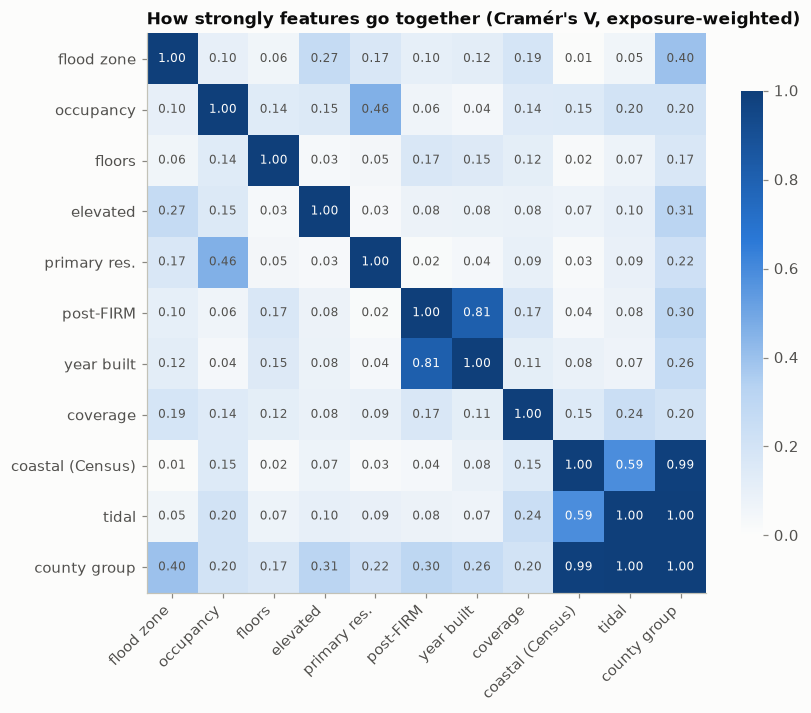

,flood_zone_group,occupancy_group,floors_group,elevated,primary_residence,post_firm,construction_band,building_coverage_band,coastal,coastal_tidal,county_group
flood_zone_group,1.00,0.10,0.06,0.27,0.17,0.10,0.12,0.19,0.01,0.05,0.40
occupancy_group,0.10,1.00,0.14,0.15,0.46,0.06,0.04,0.14,0.15,0.20,0.20
floors_group,0.06,0.14,1.00,0.03,0.05,0.17,0.15,0.12,0.02,0.07,0.17
elevated,0.27,0.15,0.03,1.00,0.03,0.08,0.08,0.08,0.07,0.10,0.31
primary_residence,0.17,0.46,0.05,0.03,1.00,0.02,0.04,0.09,0.03,0.09,0.22
post_firm,0.10,0.06,0.17,0.08,0.02,1.00,0.81,0.17,0.04,0.08,0.30
construction_band,0.12,0.04,0.15,0.08,0.04,0.81,1.00,0.11,0.08,0.07,0.26
building_coverage_band,0.19,0.14,0.12,0.08,0.09,0.17,0.11,1.00,0.15,0.24,0.20
coastal,0.01,0.15,0.02,0.07,0.03,0.04,0.08,0.15,1.00,0.59,0.99
coastal_tidal,0.05,0.20,0.07,0.10,0.09,0.08,0.07,0.24,0.59,1.00,1.00


In [20]:
assoc_feats = [f for f in FEATURES]
V = pd.DataFrame(index=assoc_feats, columns=assoc_feats, dtype=float)
for a in assoc_feats:
    for b in assoc_feats:
        V.loc[a, b] = 1.0 if a == b else ow.cramers_v(cells, a, b)
short = {"flood_zone_group": "flood zone", "occupancy_group": "occupancy", "floors_group": "floors",
         "elevated": "elevated", "primary_residence": "primary res.", "post_firm": "post-FIRM",
         "construction_band": "year built", "building_coverage_band": "coverage",
         "coastal": "coastal (Census)", "coastal_tidal": "tidal", "county_group": "county group"}
cmap = LinearSegmentedColormap.from_list("blues", [SURFACE, "#b7d3f2", BLUE, "#0f3f7a"])
fig, ax = plt.subplots(figsize=(8.2, 7))
im = ax.imshow(V.to_numpy(float), cmap=cmap, vmin=0, vmax=1)
lbl = [short[f] for f in assoc_feats]
ax.set_xticks(range(len(lbl)), lbl, rotation=45, ha="right"); ax.set_yticks(range(len(lbl)), lbl)
ax.grid(False)
for i in range(len(lbl)):
    for j in range(len(lbl)):
        v = V.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color=SURFACE if v > 0.55 else INK_2)
ax.set_title("How strongly features go together (Cramér's V, exposure-weighted)")
cb = fig.colorbar(im, ax=ax, shrink=0.75); cb.outline.set_visible(False)
save(fig, "feature_association")
plt.show()
V.round(2)

### 5b. Flood zone vs coastal, and coastal vs county
Share of each coastal group's exposure that sits in each flood zone, with the paid-claim frequency (per 1,000) in each cell.

In [21]:
def two_way(df, rows, cols):
    t = df.groupby([rows, cols], observed=True)[["exposure", "claims", "losses_2025"]].sum()
    t["frequency /1,000"] = t["claims"] / t["exposure"] * 1000
    t["pure premium"] = t["losses_2025"] / t["exposure"]
    t["share of column's exposure"] = t["exposure"] / t.groupby(level=cols)["exposure"].transform("sum")
    return t[["exposure", "share of column's exposure", "claims", "frequency /1,000", "pure premium"]]

for c in ["coastal", "coastal_tidal"]:
    print(f"\n=== flood zone x {c} ===")
    display(two_way(cells, "flood_zone_group", c).round(3))


=== flood zone x coastal ===


exposure  share of column's exposure  claims  frequency /1,000  pure premium
flood_zone_group        coastal                                                                                
A/V high risk           False    199923.158                       0.519    1644             8.223       301.211
                        True     556459.664                       0.507    5212             9.366       293.896
B/C/X moderate-low risk False    185365.026                       0.481     916             4.942       106.725
                        True     540664.919                       0.493    1785             3.301        90.893


=== flood zone x coastal_tidal ===


exposure  share of column's exposure  claims  frequency /1,000  pure premium
flood_zone_group        coastal_tidal                                                                                
A/V high risk           False           94554.178                       0.589     950            10.047       436.341
                        True           661828.645                       0.501    5906             8.924       275.755
B/C/X moderate-low risk False           66033.464                       0.411     453             6.860       175.446
                        True           659996.481                       0.499    2248             3.406        86.880

In [22]:
cg = (cells.groupby(["county_group", "coastal", "coastal_tidal"])["exposure"].sum()
           .reset_index().sort_values("exposure", ascending=False))
cg["county_group"] = cg["county_group"].map(lambda i: names.get(i, i))
mixed_census = cg.groupby("county_group")["coastal"].nunique().gt(1)
mixed_tidal = cg.groupby("county_group")["coastal_tidal"].nunique().gt(1)
print(f"County groups that mix both sides of the Census flag: {list(mixed_census[mixed_census].index)}")
print(f"County groups that mix both sides of the Tidewater flag: {list(mixed_tidal[mixed_tidal].index)}")
print(f"Cramér's V: coastal-county group {V.loc['coastal', 'county_group']:.2f}, "
      f"tidal-county group {V.loc['coastal_tidal', 'county_group']:.2f}")
cg.head(12)

County groups that mix both sides of the Census flag: ['Other tidal (small)']
County groups that mix both sides of the Tidewater flag: []
Cramér's V: coastal-county group 0.99, tidal-county group 1.00


,county_group,coastal,coastal_tidal,exposure
31,Virginia Beach city,True,True,298421.183232
22,Hampton city,True,True,158300.368912
24,Norfolk city,True,True,154652.569975
21,Chesapeake city,False,True,131133.587798
32,Other non-tidal (small),False,False,112079.988442
3,Fairfax County,True,True,75513.788293
26,Portsmouth city,True,True,55139.762415
0,Accomack County,True,True,54154.586923
25,Poquoson city,True,True,50915.588749
19,York County,True,True,50638.120817


### 5c. Confounding: one-way vs "compare like with like"
**Confounding** means a factor's one-way effect is partly (or wholly) the effect of *another* factor it travels with. The fix is to compare like with like: work out the relativity **inside each flood zone separately**, then pool (a Mantel–Haenszel rate ratio, `ow.stratified_relativity`). The table shows one-way frequency relativities next to the zone-adjusted ones, and next to ones adjusted for zone *and* year built.

In [23]:
conf = []
for f in FEATURES:
    if f in ("flood_zone_group", "county_group"):
        continue
    t = tables[f]
    adj_z = ow.stratified_relativity(cells, f, by="flood_zone_group")
    adj_zc = ow.stratified_relativity(cells, f, by=["flood_zone_group", "construction_band"])
    for lvl in t.index:
        if lvl == t.attrs["base"]:
            continue
        conf.append({"feature": f, "level": f"{LABEL.get(lvl, lvl)} vs {LABEL.get(t.attrs['base'], t.attrs['base'])}",
                     "one-way": t.loc[lvl, "frequency_rel"], "adj. for zone": adj_z[lvl],
                     "adj. for zone + year built": adj_zc[lvl]})
conf = pd.DataFrame(conf)
conf["shift from adjusting for zone"] = conf["adj. for zone"] / conf["one-way"]
conf.round(2)

,feature,level,one-way,adj. for zone,adj. for zone + year built,shift from adjusting for zone
0,occupancy_group,multi-unit residential vs single-unit residential,1.43,1.31,1.41,0.92
1,occupancy_group,non-residential vs single-unit residential,1.13,0.96,0.94,0.85
2,floors_group,1 vs 2,0.99,0.95,0.81,0.96
3,floors_group,3+ vs 2,1.11,1.14,1.30,1.02
4,elevated,yes vs no,1.08,0.86,0.99,0.80
5,primary_residence,no vs yes,1.14,0.98,0.98,0.86
6,post_firm,yes vs no,0.35,0.38,0.86,1.08
7,construction_band,1960-1979 vs 1980-1999,2.86,2.67,2.67,0.93
8,construction_band,2000 or later vs 1980-1999,0.60,0.60,0.60,1.01
9,construction_band,before 1960 vs 1980-1999,2.98,2.74,2.74,0.92


In [24]:
# The confounding example in detail: elevated buildings vs flood zone
e = cells.groupby(["flood_zone_group", "elevated"])[["exposure", "claims"]].sum()
e["frequency /1,000"] = e["claims"] / e["exposure"] * 1000
e["share of zone's exposure"] = e["exposure"] / e.groupby(level=0)["exposure"].transform("sum")
share_av = (e.xs(True, level="elevated")["exposure"] / e.xs(True, level="elevated")["exposure"].sum())
share_av_not = (e.xs(False, level="elevated")["exposure"] / e.xs(False, level="elevated")["exposure"].sum())
print(f"Elevated buildings: {share_av['A/V high risk']:.0%} of their exposure is in A/V zones; "
      f"non-elevated: {share_av_not['A/V high risk']:.0%}.")
e.round(3)

Elevated buildings: 67% of their exposure is in A/V zones; non-elevated: 40%.


exposure  claims  frequency /1,000  share of zone's exposure
flood_zone_group        elevated                                                                
A/V high risk           False     346865.223    3392             9.779                     0.459
                        True      409517.600    3464             8.459                     0.541
B/C/X moderate-low risk False     522804.506    2045             3.912                     0.720
                        True      203225.439     656             3.228                     0.280

**Confounding, with our own data: elevated buildings.**
- **One-way**, elevated buildings look slightly *riskier*: 6.72 paid claims per 1,000 policy-years vs 6.25 for non-elevated (relativity 1.08).
- **But compare like with like.** Inside the A/V high-risk zone, elevated buildings claim *less* (8.46 vs 9.78 per 1,000). Inside the B/C/X zone they also claim *less* (3.23 vs 3.91). They're lower in **every** zone, yet higher overall. This reversal is called **Simpson's paradox**.
- **Why:** 67% of elevated buildings' exposure is in A/V zones, vs 40% for non-elevated. Floodplain rules require new or substantially improved buildings in the high-risk zone to be elevated, so elevated buildings are concentrated in the riskiest places. The one-way number mixes "elevation protects you" with "elevated buildings are where the floods are." Adjusting for zone gives 0.86 (about 14% fewer claims).
- **A second example: post-FIRM vs year built.** One-way, post-FIRM buildings have 0.35× the frequency. After adjusting for zone *and* year built, it's 0.86. Most of the post-FIRM effect is really building *age* (Cramér's V between them is 0.81: most post-FIRM buildings were built after the mid-1970s). What's left (about 14% lower) is the extra benefit of being built to floodplain rules.

**Why this means we need GLMs.** Stratifying ("compare within each zone") works for one or two confounders. But we have 8 building features plus geography, and splitting by all of them at once leaves cells too thin to compare. A **GLM** (generalized linear model) estimates every factor's relativity *at the same time*, each one "holding the others fixed." It's the multi-factor version of what this section did by hand.

## 6. The coastal question: Census coastline counties vs Tidewater Virginia
**Two definitions** (both in the modelling table, see `docs/modeling_dataset.md`):
- `coastal`: the **Census Bureau's coastline-county list** (25 Virginia localities touching the ocean or a major estuary). Chesapeake, Alexandria and Arlington count as *inland*, while Fairfax, Prince William and Stafford count as *coastal* (Potomac estuary).
- `coastal_tidal`: **"Tidewater Virginia"** as defined in the **Code of Virginia, § 62.1-44.15:68** (Chesapeake Bay Preservation Act; the same localities make up Virginia's Coastal Zone Management area). 46 localities, all 25 Census ones plus 21 with tidal waters (Chesapeake, Alexandria, Arlington, Richmond city, Henrico, ...).

To see what each definition is really doing, split Virginia three ways: **Census coastal**, **Tidewater only** (the 21 added localities), and **non-tidal inland** (the rest: the Piedmont and the mountains).

Three-way coastal split  (base: Census coastal; over-dispersion phi = 461 for frequency, 138 for relativities, 3.5 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
coast3,,,,,,,,,,,,,,
Census coastal,74.0%,"6,997",6.38,6.23-6.53,3.86-10.55,1.00,1.00-1.00,"$30,396",1.00,1.00-1.00,$194,1.00,1.00,BASE
Tidewater only,15.2%,"1,157",5.15,4.86-5.45,1.49-17.75,0.81,0.39-1.68,"$23,474",0.77,0.69-0.87,$121,0.62,1.00,
non-tidal inland,10.8%,"1,403",8.74,8.29-9.21,2.84-26.88,1.37,0.70-2.69,"$37,664",1.24,1.11-1.38,$329,1.70,1.00,


Three-way coastal split  (base: Census coastal; over-dispersion phi = 56 for frequency, 37 for relativities, 4.1 for severity)


,exposure share,paid claims,"freq /1,000",Poisson 95% CI,widened 95% CI,freq rel,freq rel CI,severity,sev rel,sev rel CI,pure premium,pp rel,credibility Z,flag
coast3,,,,,,,,,,,,,,
Census coastal,74.1%,"1,464",1.66,1.58-1.75,1.13-2.44,1.00,1.00-1.00,"$21,582",1.00,1.00-1.00,$36,1.00,1.00,BASE
Tidewater only,15.3%,557,3.06,2.81-3.33,1.64-5.71,1.84,1.02-3.35,"$25,624",1.19,0.97-1.45,$78,2.19,0.72,
non-tidal inland,10.6%,"1,201",9.51,8.98-10.07,6.22-14.54,5.73,3.59-9.13,"$39,771",1.84,1.58-2.15,$378,10.55,1.00,


saved reports\figures\04_coastal_three_way.png


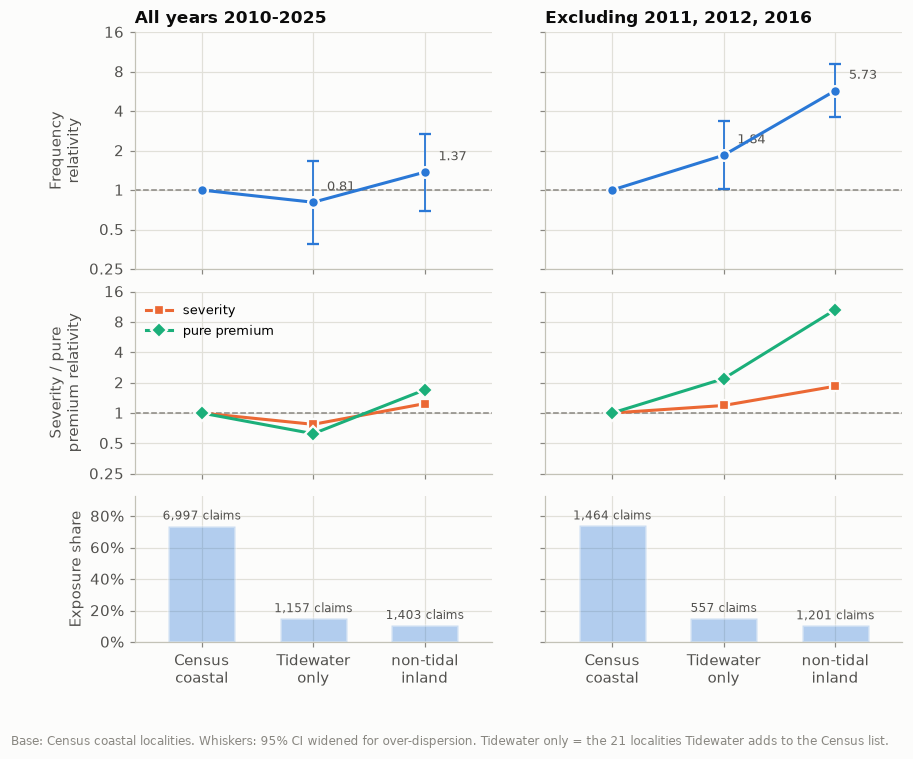

In [25]:
cells["coast3"] = np.select([cells["coastal"], cells["coastal_tidal"]],
                            ["Census coastal", "Tidewater only"], "non-tidal inland")
ORDERS["coast3"] = ["Census coastal", "Tidewater only", "non-tidal inland"]
NICE["coast3"] = "Three-way coastal split"
ex = ow.exclude_years(cells, CAT)
tables["coast3"] = ow.one_way(cells, "coast3", base="Census coastal")
t_ex = ow.one_way(ex, "coast3", base="Census coastal")
display(show_table(tables["coast3"]))
display(show_table(t_ex))

fig, axes = plt.subplots(3, 2, figsize=(9, 7.2), sharex="col", sharey="row",
                         gridspec_kw={"height_ratios": [1.3, 1, 0.8], "hspace": 0.12, "wspace": 0.15})
exhibit(axes[:, 0], tables["coast3"], "All years 2010-2025", (0.25, 16))
exhibit(axes[:, 1], t_ex, "Excluding 2011, 2012, 2016", (0.25, 16), show_ylabels=False)
axes[1, 0].legend(loc="upper left", fontsize=8.5)
fig.text(0.0, -0.02, "Base: Census coastal localities. Whiskers: 95% CI widened for over-dispersion. "
         "Tidewater only = the 21 localities Tidewater adds to the Census list.", fontsize=8, color=MUTED)
save(fig, "coastal_three_way")
plt.show()

In [26]:
# Which places make up each group? (top localities by exposure, with frequency)
loc = cells.groupby(["coast3", "county_name"])[["exposure", "claims", "losses_2025"]].sum()
loc["freq /1,000"] = loc["claims"] / loc["exposure"] * 1000
loc["pure premium"] = loc["losses_2025"] / loc["exposure"]
for g in ORDERS["coast3"]:
    print(f"\n{g}:")
    display(loc.loc[g].sort_values("exposure", ascending=False).head(8).round(1))


Census coastal:


,exposure,claims,losses_2025,"freq /1,000",pure premium
county_name,,,,,
Virginia Beach city,298421.2,2072,89196901.8,6.9,298.9
Hampton city,158300.4,834,17182425.4,5.3,108.5
Norfolk city,154652.6,1333,29942471.2,8.6,193.6
Fairfax County,75513.8,518,10267113.1,6.9,136.0
Portsmouth city,55139.8,425,11890888.0,7.7,215.6
Accomack County,54154.6,328,9708865.3,6.1,179.3
Poquoson city,50915.6,410,6885556.2,8.1,135.2
York County,50638.1,75,908639.4,1.5,17.9



Tidewater only:


,exposure,claims,losses_2025,"freq /1,000",pure premium
county_name,,,,,
Chesapeake city,131133.6,622,12314577.6,4.7,93.9
Alexandria city,18415.3,171,5286834.0,9.3,287.1
Henrico County,14576.2,49,967974.9,3.4,66.4
Chesterfield County,13777.3,37,1224586.3,2.7,88.9
Arlington County,10818.7,83,2024384.8,7.7,187.1
Richmond city,7467.4,38,858143.5,5.1,114.9
Spotsylvania County,4854.9,13,126204.5,2.7,26.0
Hanover County,3693.8,10,179575.7,2.7,48.6



non-tidal inland:


,exposure,claims,losses_2025,"freq /1,000",pure premium
county_name,,,,,
Loudoun County,12704.6,31,1019115.6,2.4,80.2
Roanoke city,8619.4,125,3295286.8,14.5,382.3
Rockingham County,7203.7,13,1113675.2,1.8,154.6
Unknown county,6776.6,8,326907.3,1.2,48.2
Roanoke County,6710.8,101,2648938.7,15.1,394.7
Salem city,6485.5,83,3806485.2,12.8,586.9
Tazewell County,4857.7,92,4871615.2,18.9,1002.9
Wise County,4748.3,48,1417066.7,10.1,298.4


### After controlling for flood zone
A two-way table: frequency per 1,000 in each zone × group, and the relativity to Census-coastal **within the same zone**. Then the zone-adjusted (Mantel–Haenszel) relativity for each binary definition, with and without cat years.

In [27]:
tw = cells.groupby(["flood_zone_group", "coast3"])[["exposure", "claims", "losses_2025"]].sum()
tw["freq /1,000"] = tw["claims"] / tw["exposure"] * 1000
tw["rel. to Census coastal, same zone"] = tw["freq /1,000"] / tw["freq /1,000"].xs("Census coastal", level=1).reindex(tw.index, level=0)
tw["pure premium"] = tw["losses_2025"] / tw["exposure"]
display(tw.round(2))

adj = []
for f in ["coastal", "coastal_tidal"]:
    for nm, d in [("all years", cells), ("excl. cat years", ex)]:
        oneway = ow.one_way(d, f, base=True, phi_freq=1, phi_rel=1, phi_sev=1)
        adj.append({"definition": f, "years": nm,
                    "inland exposure share": oneway.loc[False, "exposure_share"],
                    "one-way freq rel (inland vs coastal)": oneway.loc[False, "frequency_rel"],
                    "zone-adjusted freq rel": ow.stratified_relativity(d, f, base=True)[False],
                    "severity rel": oneway.loc[False, "severity_rel"],
                    "pure premium rel": oneway.loc[False, "pure_premium_rel"]})
pd.DataFrame(adj).round(2)

exposure  claims   losses_2025  freq /1,000  rel. to Census coastal, same zone  pure premium
flood_zone_group        coast3                                                                                                         
A/V high risk           Census coastal    556459.66    5212  1.635412e+08         9.37                               1.00        293.90
                        Tidewater only    105368.98     694  1.896118e+07         6.59                               0.70        179.95
                        non-tidal inland   94554.18     950  4.125787e+07        10.05                               1.07        436.34
B/C/X moderate-low risk Census coastal    540664.92    1785  4.914266e+07         3.30                               1.00         90.89
                        Tidewater only    119331.56     463  8.197826e+06         3.88                               1.18         68.70
                        non-tidal inland   66033.46     453  1.158528e+07         6.86                               2.08        175.45

,definition,years,inland exposure share,one-way freq rel (inland vs coastal),zone-adjusted freq rel,severity rel,pure premium rel
0,coastal,all years,0.26,1.04,1.03,1.03,1.07
1,coastal,excl. cat years,0.26,3.43,3.43,1.64,5.61
2,coastal_tidal,all years,0.11,1.42,1.32,1.28,1.81
3,coastal_tidal,excl. cat years,0.11,5.00,4.96,1.75,8.77


### An objective score: which definition separates risk better?
Fit three small **Poisson GLMs** for paid-claim counts (with log exposure as the **offset**, so the model predicts a rate). All three include flood zone and year (year soaks up the storm-to-storm swings):
- **M0:** zone + year
- **M1:** zone + year + Census `coastal`
- **M2:** zone + year + `coastal_tidal`
- **M3:** zone + year + both flags (= the three-way split, 2 parameters)

The **drop in deviance** from M0 says how much each definition adds. Dividing by the over-dispersion φ gives a quasi-likelihood χ² (≈ 1 per added parameter if the flag is pure noise; above 3.84 for 1 parameter, or 5.99 for 2, ≈ "significant at 5%"). **AIC** (Akaike information criterion = deviance-style misfit + 2 × number of parameters; lower is better) is shown too, but it assumes no over-dispersion, so it over-rewards extra parameters here. We also fit on the non-cat years only.

In [28]:
def glm_compare(df):
    g = (df[df["exposure"] > 0].groupby(["year", "flood_zone_group", "coastal", "coastal_tidal"])
           [["exposure", "claims"]].sum().reset_index())
    def fit(terms):
        X = pd.get_dummies(g[terms].astype(str), drop_first=True, dtype=float)
        X = sm.add_constant(X)
        return sm.GLM(g["claims"], X, family=sm.families.Poisson(), offset=np.log(g["exposure"])).fit()
    m0 = fit(["flood_zone_group", "year"])
    m_full = fit(["flood_zone_group", "year", "coastal", "coastal_tidal"])
    phi = m_full.pearson_chi2 / m_full.df_resid             # over-dispersion from the biggest model
    out = []
    for nm, terms in [("M1: + coastal (Census)", ["flood_zone_group", "year", "coastal"]),
                      ("M2: + coastal_tidal (Tidewater)", ["flood_zone_group", "year", "coastal_tidal"]),
                      ("M3: + both flags (3-way split)", ["flood_zone_group", "year", "coastal", "coastal_tidal"])]:
        m = fit(terms)
        drop = m0.deviance - m.deviance
        k = len(terms) - 2                                  # flags added (1 or 2 parameters)
        out.append({"model": nm, "added parameters": k, "deviance drop vs M0": drop, "phi": phi,
                    "quasi chi-square": drop / phi, "5% critical value": [3.84, 5.99][k - 1], "AIC": m.aic})
    return pd.DataFrame(out).set_index("model")

print("All years:"); display(glm_compare(cells).round(2))
print("Excluding 2011, 2012, 2016:"); display(glm_compare(ex).round(2))

All years:


,added parameters,deviance drop vs M0,phi,quasi chi-square,5% critical value,AIC
model,,,,,,
M1: + coastal (Census),1,0.43,69.12,0.01,3.84,5019.96
M2: + coastal_tidal (Tidewater),1,38.75,69.12,0.56,3.84,4981.65
M3: + both flags (3-way split),2,74.98,69.12,1.08,5.99,4947.41


Excluding 2011, 2012, 2016:


,added parameters,deviance drop vs M0,phi,quasi chi-square,5% critical value,AIC
model,,,,,,
M1: + coastal (Census),1,1098.11,18.52,59.3,3.84,1988.30
M2: + coastal_tidal (Tidewater),1,1425.94,18.52,77.0,3.84,1660.47
M3: + both flags (3-way split),2,1559.30,18.52,84.2,5.99,1529.10


In [29]:
# Year by year: does non-tidal inland have higher frequency in most years, or only some?
yr3 = cells.groupby(["year", "coastal_tidal"])[["exposure", "claims"]].sum().unstack()
f3 = yr3["claims"] / yr3["exposure"]
r3 = (f3[False] / f3[True]).rename("non-tidal / tidal frequency")
share = (yr3["claims"][False] / yr3["claims"].sum(axis=1)).rename("non-tidal share of paid claims")
pd.concat([r3, share, yr3["claims"][False].rename("non-tidal claims")], axis=1).round(2).T

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
non-tidal / tidal frequency,2.72,0.23,0.13,22.52,0.85,2.70,0.33,3.12,9.78,0.96,5.41,1.73,3.91,2.28,29.31,10.21
non-tidal share of paid claims,0.27,0.03,0.02,0.75,0.10,0.26,0.04,0.28,0.53,0.10,0.38,0.16,0.30,0.20,0.75,0.51
non-tidal claims,65.00,84.00,21.00,173.00,31.00,94.00,97.00,23.00,329.00,28.00,161.00,24.00,33.00,11.00,139.00,90.00


**Recommendation: use the Tidewater definition (`coastal_tidal`), not the Census list.**
1. **The Census flag separates nothing overall.** Inland vs coastal frequency is 1.04, and the deviance gain is 0.4 (pure noise). The reason: its "inland" group lumps tidal Hampton Roads/Northern Virginia cities with *low* frequency (Chesapeake 4.7 per 1,000) together with mountain localities with *high* frequency (Roanoke city 14.5, Tazewell 18.9), and the two cancel out.
2. **Tidewater separates them.** Its non-tidal group is the Piedmont and the mountains: 1.42× the frequency one-way, 1.32× after controlling for flood zone, and 1.81× the pure premium. It wins in every comparison: deviance gain 39 vs 0.4 (all years), 1,426 vs 1,098 (excluding cat years), and AIC. It's also the definition with a statutory source (Code of Virginia § 62.1-44.15:68).
3. **But no single coastal relativity is stable**, so don't over-trust it. In hurricane years the coast is far riskier (non-tidal 0.25×). In normal years, inland is far riskier (5.0×). Once over-dispersion is accounted for, the all-years effect is not statistically significant (quasi χ² 0.56). Virginia has **two flood regimes**: rare, huge coastal storm-surge events, and frequent, steadier inland river and flash flooding. The model needs to capture both, so the stability checks in validation should look at cat and non-cat years separately.
4. **The three-way split** (both flags together: Census coastal / Tidewater-only / non-tidal) fits better still, because the 21 Tidewater-only localities behave differently from both groups (0.81× all years, 1.84× without cat years). Since `coastal` and `coastal_tidal` are both in the table, week 3 can test this as a 2-parameter region effect.
5. **Overlap with county:** every county group is entirely on one side of the Tidewater flag (Cramér's V = 1.00), and of the Census flag too, except the pooled `Other tidal (small)` group. So in a model that already has `county_group`, the coastal flag adds nothing for the 32 credible counties. It matters for the pooled small counties, for a simpler model without county, and for the app's explanations.

**Acted on:** small counties are now pooled by Tidewater (`Other tidal (small)` / `Other non-tidal (small)`). The old `Other inland (small)` pool mixed tidal localities (5.5 per 1,000) with non-tidal ones (9.3 per 1,000).

## 7. Validation preview: why the choice of test years matters
The full design is in `docs/validation_plan.md` (code: `src/validation.py`). Two candidate schemes:
- **(a) Time holdout:** train on 2010–2020, test on 2021–2025.
- **(b) Leave-one-year-out (LOYO) cross-validation:** 16 rounds; each time, train on 15 years and test on the year left out.

The chart shows what each test set contains: paid claims per year (catastrophe years in orange), and the share of each year's claims that came from non-tidal inland counties.

,test_year,cat_year,train_years,train_exposure,train_claims,test_exposure,test_claims,test_losses_2025
0,2010,False,15,1385105.0,9312,97308.0,245,3775359.0
1,2011,True,15,1383372.0,6762,99041.0,2795,60307246.0
2,2012,True,15,1380625.0,8360,101788.0,1197,34558717.0
3,2013,False,15,1379228.0,9327,103184.0,230,4948690.0
4,2014,False,15,1381904.0,9252,100509.0,305,9353425.0
5,2015,False,15,1385546.0,9199,96867.0,358,6943888.0
6,2016,True,15,1389903.0,7214,92510.0,2343,104187282.0
7,2017,False,15,1390331.0,9475,92082.0,82,2093096.0
8,2018,False,15,1388156.0,8942,94256.0,615,22414490.0
9,2019,False,15,1387023.0,9276,95390.0,281,10828719.0


saved reports\figures\04_validation_folds.png


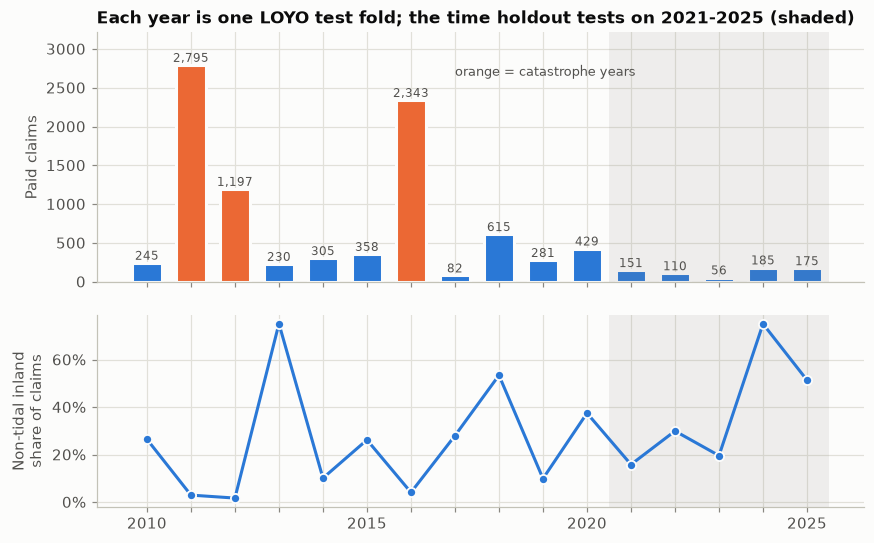

Time holdout: train 8,880 paid claims (2010-2020), test 677 (2021-2025).
Non-tidal inland share of claims: 12.5% in 2010-2020 vs 43.9% in 2021-2025.


In [30]:
fs = val.fold_summary(val.leave_one_year_out(cells))
display(fs.round(0))
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, gridspec_kw={"hspace": 0.15, "height_ratios": [1.3, 1]})
colors = [ORANGE if c else BLUE for c in fs["cat_year"]]
a1.bar(fs["test_year"], fs["test_claims"], color=colors, width=0.7, edgecolor=SURFACE, linewidth=2)
for x, n in zip(fs["test_year"], fs["test_claims"]):
    a1.annotate(f"{n:,}", (x, n), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=8, color=INK_2)
a1.set_ylabel("Paid claims"); a1.set_ylim(0, fs["test_claims"].max() * 1.15)
a1.set_title("Each year is one LOYO test fold; the time holdout tests on 2021-2025 (shaded)")
a2.plot(share.index, share * 100, color=BLUE, lw=2, marker="o", ms=6, mec=SURFACE, mew=1.2)
a2.set_ylabel("Non-tidal inland\nshare of claims")
a2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:.0f}%"))
for ax in (a1, a2):
    ax.axvspan(2020.5, 2025.5, color=MUTED, alpha=0.12, lw=0)
a2.set_xticks(range(2010, 2026, 1), [str(y) if y % 5 == 0 else "" for y in range(2010, 2026)])
a1.text(2017, fs["test_claims"].max() * 0.95, "orange = catastrophe years", color=INK_2, fontsize=8.5)
save(fig, "validation_folds")
plt.show()
print(f"Time holdout: train {train['claims'].sum():,} paid claims (2010-2020), test {test['claims'].sum():,} (2021-2025).")
print(f"Non-tidal inland share of claims: {train.loc[~train.coastal_tidal, 'claims'].sum() / train['claims'].sum():.1%} in "
      f"2010-2020 vs {test.loc[~test.coastal_tidal, 'claims'].sum() / test['claims'].sum():.1%} in 2021-2025.")

**Reading this:**
- **The 2021–2025 holdout contains no catastrophe year** (677 paid claims in total, vs 8,880 in 2010–2020), and its claims come from a different place. **44% came from non-tidal inland counties, vs 12.5% in 2010–2020** (2024 alone: 75%, the year Hurricane Helene's remnants flooded southwest Virginia). A model trained on hurricane-heavy 2010–2020 is being tested on a different mix of flooding. One 5-year window is a single draw of the weather.
- **Leave-one-year-out** gives 16 separate tests, each a different kind of year: 3 hurricane years, inland-dominated years (2013, 2018, 2024), and quiet years. That shows whether one model beats another *consistently*, not just in one window. Its weakness: when it tests on, say, 2012, the model has trained on later years. That's mild here, because the relativities (unlike the overall level) show no strong trend.
- **Decision** (details in `docs/validation_plan.md`): LOYO is the main model comparison, with each year scored separately and summarized with and without cat years. The 2021–2025 forward holdout is kept as a one-time final check.

## 8. Save a summary for the report
Key numbers go to `data/processed/one_way_summary.json` (not in Git), so `reports/03_one_way_findings.md` can be checked against them.

In [31]:
summary = {
    "statewide": {"frequency_per_1000": FREQ * 1000, "severity": SEV, "pure_premium": PP},
    "importance": imp.round(4).reset_index().to_dict(orient="records"),
    "stability": stability.round(4).reset_index().to_dict(orient="records"),
    "confounding": conf.round(4).to_dict(orient="records"),
    "one_way": {f: tables[f].reset_index().astype({f: str}).round(5).to_dict(orient="records")
                for f in tables},
    "coastal_adjusted": pd.DataFrame(adj).round(4).to_dict(orient="records"),
}
out = ROOT / "data" / "processed" / "one_way_summary.json"
out.write_text(json.dumps(summary, indent=1, default=str), encoding="utf-8")
print("saved", out.relative_to(ROOT))

saved data\processed\one_way_summary.json
